<a href="https://colab.research.google.com/github/Noadori34/Project-data-science/blob/main/notebooks/01_kidney_ultrasound_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Phase 1: Loading, Checking data types, Preparing for EDA

In [1]:
#!git clone https://github.com/Noadori34/Project-data-science.git

Cloning into 'Project-data-science'...
remote: Enumerating objects: 8248, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 8248 (delta 8), reused 20 (delta 3), pack-reused 8218 (from 1)
Receiving objects: 100% (8248/8248), 198.14 MiB | 18.21 MiB/s, done.
Resolving deltas: 100% (553/553), done.
Updating files: 100% (8677/8677), done.


In [2]:
#%cd /content/Project-data-science
#!ls -la

/content/Project-data-science
total 72
drwxr-xr-x 7 root root  4096 Oct 14 10:43 .
drwxr-xr-x 1 root root  4096 Oct 14 10:43 ..
drwxr-xr-x 5 root root  4096 Oct 14 10:43 bbdd_kidney
-rw-r--r-- 1 root root  2527 Oct 14 10:43 description.md
drwxr-xr-x 2 root root  4096 Oct 14 10:43 Documents
drwxr-xr-x 8 root root  4096 Oct 14 10:43 .git
-rw-r--r-- 1 root root    24 Oct 14 10:43 .gitignore
drwxr-xr-x 2 root root 36864 Oct 14 10:43 kidneyUS_images_25_june_2025
drwxr-xr-x 4 root root  4096 Oct 14 10:43 kidneyUS-main


In [4]:
from collections import Counter
from pathlib import Path

root = Path("/content/Project-data-science")

for folder in ["bbdd_kidney", "kidneyUS-main",
               "kidneyUS_images_25_june_2025"]:

    path = root / folder

    extensions = Counter(
        file.suffix.lower()
        for file in path.rglob("*")
        if file.is_file()
    )

    print(f"\n{folder}")
    print(extensions)


bbdd_kidney
Counter({'.mat': 1985, '.txt': 1985, '.jpg': 1985, '': 1})

kidneyUS-main
Counter({'.png': 2137, '.py': 30, '': 3, '.csv': 2, '.txt': 1, '.xlsx': 1, '.docx': 1, '.md': 1, '.pdf': 1})

kidneyUS_images_25_june_2025
Counter({'.png': 534, '.csv': 2})


In [5]:
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU: Tesla T4


### Phase 2:  EDA (Exploratory Data Analysis)


First, we need to inspect our data and understand how classification labels are represented

In [8]:

from pathlib import Path

root = Path("/content/Project-data-science")
labels_dir = root / "bbdd_kidney" / "labels"

label_files = sorted(
    labels_dir.glob("*.txt"),
    key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem
)

print("Total label files:", len(label_files))

for file in label_files[:10]:
    print(f"\n{'='*45}")
    print("File:", file.name)
    print("Content:")
    print(file.read_text(encoding="utf-8", errors="replace")[:1500])


Total label files: 1985

File: 1.txt
Content:
Image filename: 1.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 326 196 48 32 5


File: 2.txt
Content:
Image filename: 2.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 299 225 31 34 5


File: 3.txt
Content:
Image filename: 3.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 226 194 106 76 5


File: 4.txt
Content:
Image filename: 4.jpg
Global diagnosis: 1
Global pathologies: 1 0
View: 0


File: 5.txt
Content:
Image filename: 5.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 408 186 94 77 1
Bounding box 2: 323 152 62 52 9


File: 6.txt
Content:
Image filename: 6.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 353 190 121 78 7


File: 7.txt
Content:
Image filename: 7.jpg
Global diagnosis: 1
Global pathologies: 0 0
View: 0
Bounding box 1: 211 158 85 45 9


File: 8.txt
Content:
Image filename: 8.jpg
Global diagnosis: 1
Global 

Number of images and annotation styles:

In [9]:

from pathlib import Path

root = Path("/content/Project-data-science")

folders = {
    "Classification images": root / "bbdd_kidney/images",
    "Classification labels": root / "bbdd_kidney/labels",
    "Segmentation masks": root / "bbdd_kidney/masks",
    "Open Kidney images": root / "kidneyUS_images_25_june_2025"
}

for name, folder in folders.items():
    files = [p for p in folder.iterdir() if p.is_file()]
    print(f"{name}: {len(files)}")


Classification images: 1985
Classification labels: 1985
Segmentation masks: 1985
Open Kidney images: 536


In [10]:
# Every classification image has label and mask?


images = {p.stem for p in (root / "bbdd_kidney/images").glob("*.jpg")}
labels = {p.stem for p in (root / "bbdd_kidney/labels").glob("*.txt")}
masks = {p.stem for p in (root / "bbdd_kidney/masks").glob("*.mat")}

print("Images:", len(images))
print("Labels:", len(labels))
print("Masks:", len(masks))

print("Images without labels:", len(images - labels))
print("Images without masks:", len(images - masks))
print("Labels without images:", len(labels - images))


Images: 1985
Labels: 1985
Masks: 1985
Images without labels: 0
Images without masks: 0
Labels without images: 0


In [11]:
# Extract all diagnosis labels:


from pathlib import Path
from collections import Counter

root = Path("/content/Project-data-science")
labels_dir = root / "bbdd_kidney" / "labels"

diagnoses = []
global_pathologies = []
views = []
bbox_classes = []

for file in sorted(labels_dir.glob("*.txt")):
    lines = file.read_text(
        encoding="utf-8", errors="replace"
    ).splitlines()

    for line in lines:
        if line.startswith("Global diagnosis:"):
            diagnoses.append(line.split(":", 1)[1].strip())

        elif line.startswith("Global pathologies:"):
            global_pathologies.append(
                line.split(":", 1)[1].strip()
            )

        elif line.startswith("View:"):
            views.append(line.split(":", 1)[1].strip())

        elif line.startswith("Bounding box"):
            values = line.split(":", 1)[1].split()
            if len(values) >= 5:
                bbox_classes.append(values[4])

print("GLOBAL DIAGNOSIS DISTRIBUTION")
print(Counter(diagnoses))

print("\nGLOBAL PATHOLOGIES")
print(Counter(global_pathologies))

print("\nVIEW DISTRIBUTION")
print(Counter(views))

print("\nBOUNDING BOX CLASSES")
print(Counter(bbox_classes))

print("\nNumber of diagnoses:", len(diagnoses))


GLOBAL DIAGNOSIS DISTRIBUTION
Counter({'1': 1535, '0': 450})

GLOBAL PATHOLOGIES
Counter({'0 0': 1276, '1 1': 395, '1 0': 200, '0 1': 114})

VIEW DISTRIBUTION
Counter({'0': 1842, '1': 143})

BOUNDING BOX CLASSES
Counter({'2': 1073, '7': 618, '4': 384, '8': 111, '1': 110, '3': 92, '9': 45, '5': 34, '6': 11})

Number of diagnoses: 1985


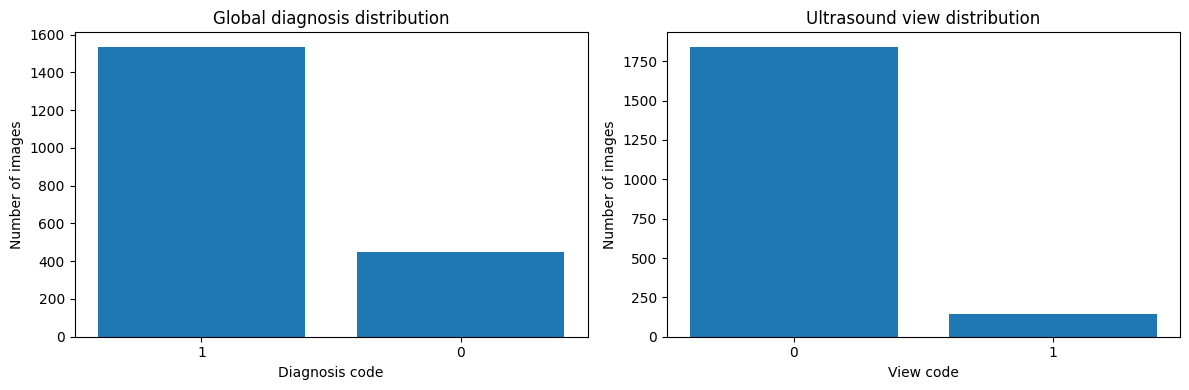

In [12]:
# Generate first charts:


import matplotlib.pyplot as plt
from collections import Counter

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

diagnosis_counts = Counter(diagnoses)

axes[0].bar(
    diagnosis_counts.keys(),
    diagnosis_counts.values()
)
axes[0].set_title("Global diagnosis distribution")
axes[0].set_xlabel("Diagnosis code")
axes[0].set_ylabel("Number of images")

view_counts = Counter(views)

axes[1].bar(
    view_counts.keys(),
    view_counts.values()
)
axes[1].set_title("Ultrasound view distribution")
axes[1].set_xlabel("View code")
axes[1].set_ylabel("Number of images")

plt.tight_layout()
plt.show()


We inspected the structure of the two available kidney ultrasound datasets. The main classification dataset contains 1,985 JPEG ultrasound images, 1,985 text annotation files and 1,985 MATLAB segmentation files.

Each image has a corresponding annotation and mask filename, with no missing matches. The annotations provide image-level diagnosis codes, global pathology indicators, ultrasound view information and bounding boxes for localized findings. We are now validating the diagnostic label encoding and analyzing the class distribution before training a preliminary CNN.